# 📊 Exploratory Data Analysis (EDA) Report: Depression Detection Dataset
**File analyzed:** `d:/projects/DepDet/anon_processed_df_parquet`  
**Dataset context:** Longitudinal actigraphy (wearable physical activity & sleep data), clinical survey assessments (PHQ-9 depression scores), demographics, and comorbidity history.

---

### Executive Summary & Key Findings
1. **Dataset Scale & Structure:** 
   - **35,694 total longitudinal observations** spanning **4,948 unique participants** (`user_id`).
   - Each participant has between 1 and 12 longitudinal observation periods (mean = 7.2 periods per user).
   - Contains **154 features** encompassing physical activity, sleep quality, circadian rhythm consistency, clinical survey outcomes, demographics, and comorbidities.

2. **Depression Target Profile (PHQ-9 Assessment):**
   - **10,866 observation intervals** contain matched PHQ-9 depression assessment scores (30.4% labeled coverage, 69.6% unmonitored/inter-survey intervals).
   - Mean PHQ-9 score: **7.66 ± 6.03** (range: 0 - 27).
   - **Severity Distribution:** None/Minimal (37.0%), Mild (30.1%), Moderate (18.2%), Moderately Severe (9.7%), Severe (5.0%).

3. **Digital Biomarkers of Depression (Wearable Sensor Insights):**
   - 🚶 **Physical Activity Decline:** A strong, linear monotonic decline in daily active step count with worsening depression severity. Non-depressed participants average **9,463 steps/day**, whereas severely depressed participants average only **6,980 steps/day** (a **26.2% reduction**).
   - 😴 **Sleep Fragmentation & Inefficiency:** Weekday sleep efficiency (`sleep_ratio_asleep_in_bed`) decreases from **90.9%** (Minimal) to **84.8%** (Severe). Severe patients remain in bed 34 minutes longer on average without gaining additional sleep time.
   - 📉 **Sleep Variability:** Sleep duration variability (IQR) increases by **31.2%** in severe depression (96.2 min vs 126.1 min), reflecting erratic sleep schedules.
   - ⏰ **Circadian Latency:** Bedtime shifted later by **~45 minutes** in severe depression (10:44 PM vs 11:27 PM median bedtime).

4. **Clinical & Socioeconomic Correlates:**
   - Strongest positive clinical predictors of higher PHQ-9 score: **Comorbid Migraines** ($r = +0.353$), **Financial Strain/Money Stress** ($r = +0.351$), **Neuropathic Pain** ($r = +0.335$), **Migraine Days/Month** ($r = +0.291$), and **Sedentary Days Count** ($r = +0.229$).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set aesthetic visual theme
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'font.sans-serif': 'DejaVu Sans', 'font.family': 'sans-serif'})

# Load the dataset
parquet_path = 'd:/projects/DepDet/anon_processed_df_parquet'
df = pd.read_parquet(parquet_path)

# Extract user_id and period index
user_period = df.index.str.split('_', expand=True)
df['user_id'] = user_period.get_level_values(0)
df['period_num'] = user_period.get_level_values(1).astype(int)

print(f"Dataset Successfully Loaded!")
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]:,} columns")
print(f"Unique Users: {df['user_id'].nunique():,}")


Dataset Successfully Loaded!
Shape: 35,694 rows × 156 columns
Unique Users: 4,948


---
## 1. Dataset Dimensions & Longitudinal Structure Analysis
Understanding the longitudinal framework, observation periods per subject, and memory footprint.


=== User Participation Summary ===
Total Unique Users: 4,948
Min Periods per User: 1
Max Periods per User: 12
Mean Periods per User: 7.21 ± 3.93
Median Periods per User: 8


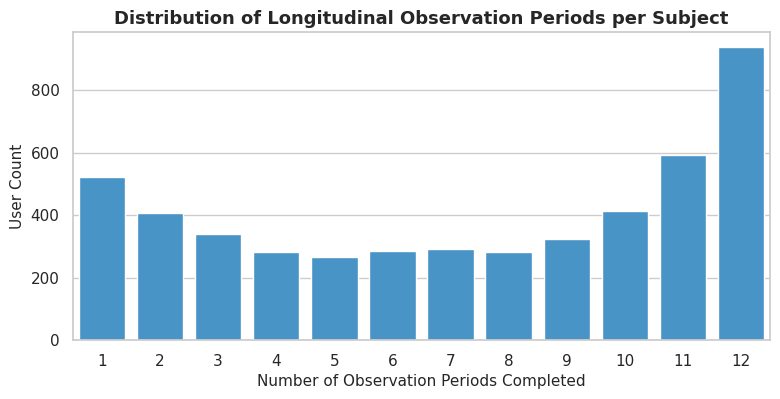

In [2]:
# Calculate participation metrics
user_period_counts = df.groupby('user_id')['period_num'].count()

print("=== User Participation Summary ===")
print(f"Total Unique Users: {df['user_id'].nunique():,}")
print(f"Min Periods per User: {user_period_counts.min()}")
print(f"Max Periods per User: {user_period_counts.max()}")
print(f"Mean Periods per User: {user_period_counts.mean():.2f} ± {user_period_counts.std():.2f}")
print(f"Median Periods per User: {user_period_counts.median():.0f}")

plt.figure(figsize=(9, 4))
sns.countplot(x=user_period_counts, color='#3498db')
plt.title('Distribution of Longitudinal Observation Periods per Subject', fontsize=13, fontweight='bold')
plt.xlabel('Number of Observation Periods Completed', fontsize=11)
plt.ylabel('User Count', fontsize=11)
plt.show()


---
## 2. Missing Value Profiling & Data Completeness Tiering
Analysis of missing data across the 154 features to identify high-quality predictors vs sparse indicators.


=== Feature Completeness Tiers ===
Complete (0% missing): 41 features
High Quality (<5% missing): 39 features
Moderate (5% - 30% missing): 44 features
Sparse (30% - 70% missing): 28 features
Very Sparse (>=70% missing): 4 features


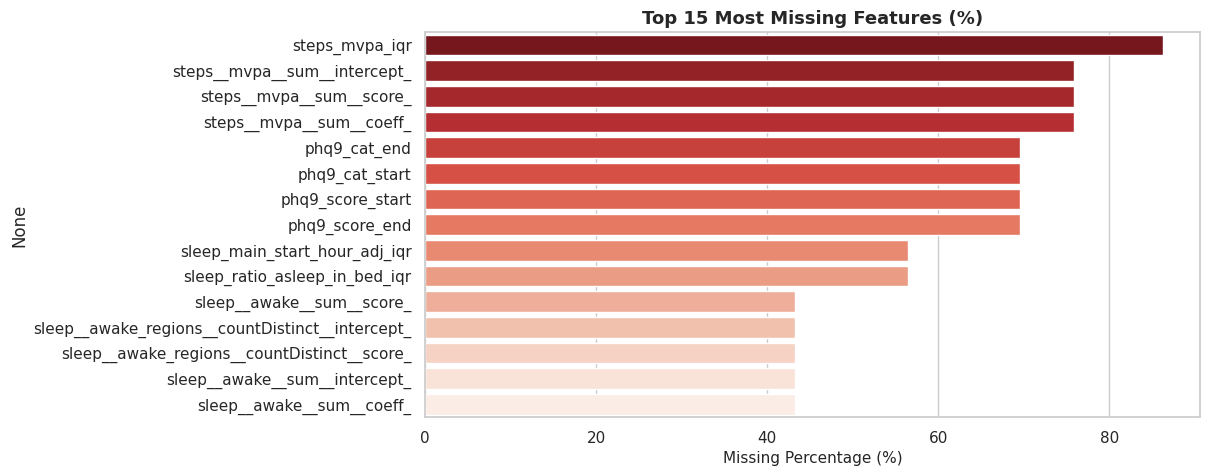

In [3]:
null_pct = df.isnull().mean() * 100

tier_complete = (null_pct == 0).sum()
tier_high = ((null_pct > 0) & (null_pct < 5)).sum()
tier_medium = ((null_pct >= 5) & (null_pct < 30)).sum()
tier_sparse = ((null_pct >= 30) & (null_pct < 70)).sum()
tier_very_sparse = (null_pct >= 70).sum()

print("=== Feature Completeness Tiers ===")
print(f"Complete (0% missing): {tier_complete} features")
print(f"High Quality (<5% missing): {tier_high} features")
print(f"Moderate (5% - 30% missing): {tier_medium} features")
print(f"Sparse (30% - 70% missing): {tier_sparse} features")
print(f"Very Sparse (>=70% missing): {tier_very_sparse} features")

# Top 15 missing columns
top_missing = null_pct.sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_missing.values, y=top_missing.index, palette='Reds_r')
plt.title('Top 15 Most Missing Features (%)', fontsize=13, fontweight='bold')
plt.xlabel('Missing Percentage (%)', fontsize=11)
plt.show()


---
## 3. Target Variable Analysis: PHQ-9 Depression Severity Scores
Profiling the primary target variables (`phq9_score_start`, `phq9_cat_start`, `phq9_score_end`, `phq9_cat_end`).


=== PHQ-9 Statistical Summary ===


       phq9_score_start  phq9_score_end  phq9_cat_start  phq9_cat_end
count      10866.000000    10866.000000    10866.000000  10866.000000
mean           7.661881        7.467605        1.155255      1.116602
std            6.028646        6.037733        1.168189      1.159894
min            0.000000        0.000000        0.000000      0.000000
25%            3.000000        3.000000        0.000000      0.000000
50%            6.000000        6.000000        1.000000      1.000000
75%           11.000000       11.000000        2.000000      2.000000
max           27.000000       27.000000        4.000000      4.000000


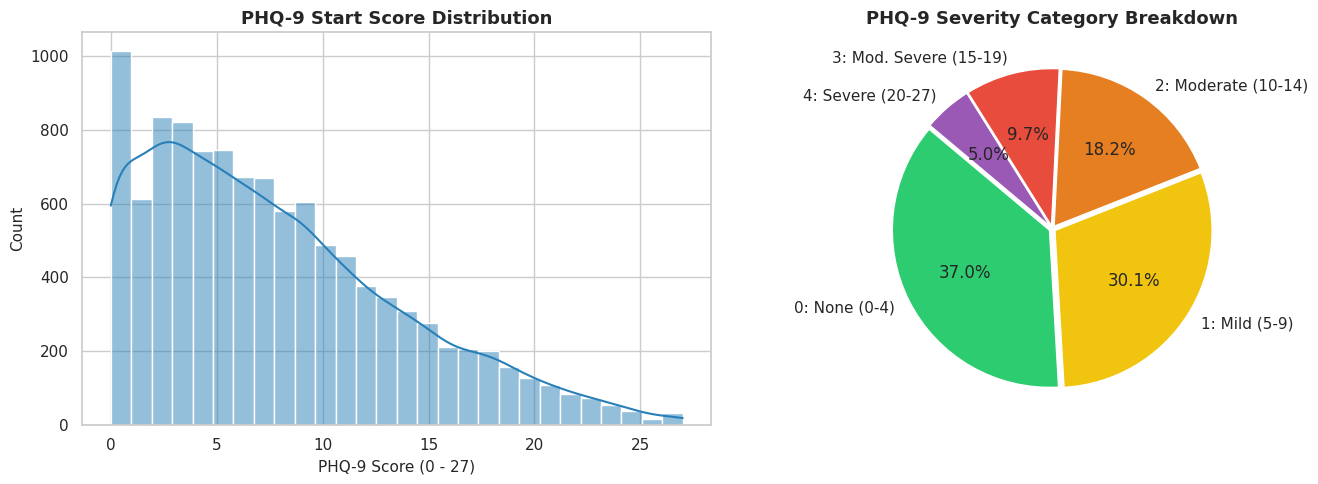

In [4]:
target_cols = ['phq9_score_start', 'phq9_score_end', 'phq9_cat_start', 'phq9_cat_end']
print("=== PHQ-9 Statistical Summary ===")
print(df[target_cols].describe())

valid_phq = df.dropna(subset=['phq9_cat_start']).copy()
cat_labels = ['0: None (0-4)', '1: Mild (5-9)', '2: Moderate (10-14)', '3: Mod. Severe (15-19)', '4: Severe (20-27)']
valid_phq['severity_label'] = valid_phq['phq9_cat_start'].map(dict(enumerate(cat_labels)))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(valid_phq['phq9_score_start'], kde=True, bins=28, color='#2980b9', ax=axes[0])
axes[0].set_title('PHQ-9 Start Score Distribution', fontsize=13, fontweight='bold')
axes[0].set_xlabel('PHQ-9 Score (0 - 27)', fontsize=11)
axes[0].set_ylabel('Count', fontsize=11)

cat_counts = valid_phq['severity_label'].value_counts()[cat_labels]
colors = ['#2ecc71', '#f1c40f', '#e67e22', '#e74c3c', '#9b59b6']
axes[1].pie(cat_counts, labels=cat_labels, autopct='%1.1f%%', colors=colors, startangle=140, explode=[0.02]*5)
axes[1].set_title('PHQ-9 Severity Category Breakdown', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()


---
## 4. Digital Biomarkers: Physical Activity & Motion Dynamics
Examining the association between actigraphy step metrics and depression severity levels.


=== Mean Actigraphy Metrics by PHQ-9 Severity ===
                        steps_awake_mean  steps_mvpa_sum_recent  \
severity_label                                                    
0: None (0-4)                    9463.00                  64.35   
1: Mild (5-9)                    8348.73                  46.54   
2: Moderate (10-14)              7798.95                  40.55   
3: Mod. Severe (15-19)           7190.56                  35.97   
4: Severe (20-27)                6979.52                  33.02   

                        steps_lpa_sum_recent  steps__active_day_count_  \
severity_label                                                           
0: None (0-4)                         168.55                      2.61   
1: Mild (5-9)                         148.92                      2.05   
2: Moderate (10-14)                   134.03                      1.79   
3: Mod. Severe (15-19)                121.57                      1.52   
4: Severe (20-27)                   

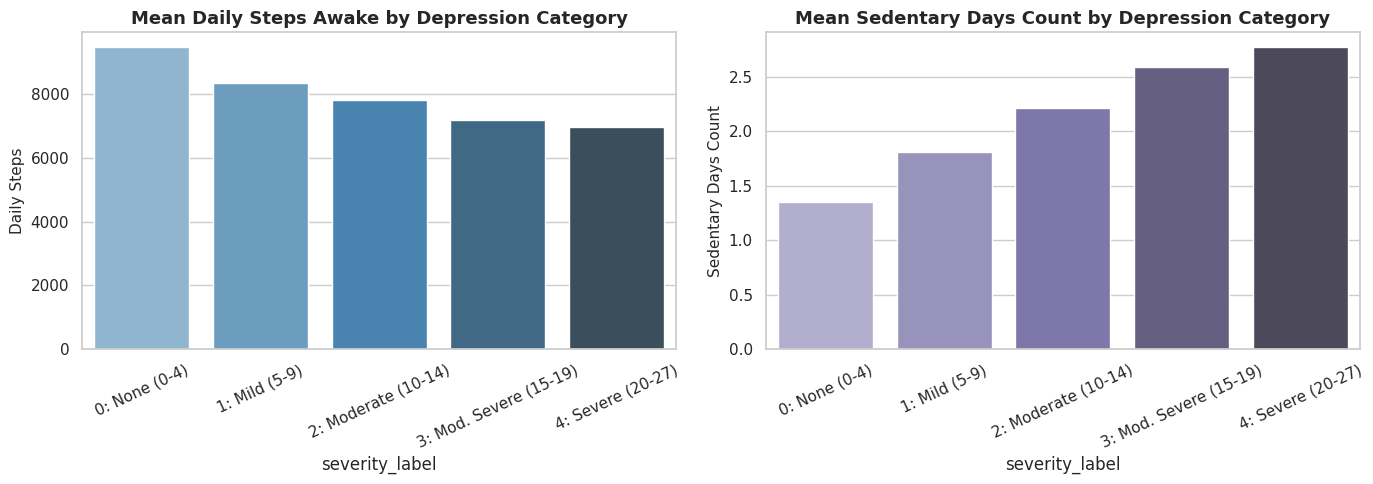

In [5]:
activity_metrics = ['steps_awake_mean', 'steps_mvpa_sum_recent', 'steps_lpa_sum_recent', 'steps__active_day_count_', 'steps__sedentary_day_count_']

act_summary = valid_phq.groupby('severity_label')[activity_metrics].mean()
print("=== Mean Actigraphy Metrics by PHQ-9 Severity ===")
print(act_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(x=act_summary.index, y=act_summary['steps_awake_mean'], palette='Blues_d', ax=axes[0])
axes[0].set_title('Mean Daily Steps Awake by Depression Category', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Daily Steps', fontsize=11)
axes[0].tick_params(axis='x', rotation=25)

sns.barplot(x=act_summary.index, y=act_summary['steps__sedentary_day_count_'], palette='Purples_d', ax=axes[1])
axes[1].set_title('Mean Sedentary Days Count by Depression Category', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Sedentary Days Count', fontsize=11)
axes[1].tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()


---
## 5. Digital Biomarkers: Sleep Architecture & Circadian Rhythms
Evaluating sleep duration, sleep efficiency, sleep duration variability (IQR), and bedtime latency across depression categories.


=== Sleep Architecture Summary across Depression Categories ===
                        sleep_asleep_weekday_mean  sleep_in_bed_weekday_mean  \
severity_label                                                                 
0: None (0-4)                              360.56                     397.45   
1: Mild (5-9)                              367.86                     414.38   
2: Moderate (10-14)                        369.62                     427.14   
3: Mod. Severe (15-19)                     363.18                     426.25   
4: Severe (20-27)                          364.63                     431.07   

                        sleep_ratio_asleep_in_bed_weekday_mean  \
severity_label                                                   
0: None (0-4)                                             0.91   
1: Mild (5-9)                                             0.89   
2: Moderate (10-14)                                       0.87   
3: Mod. Severe (15-19)                       

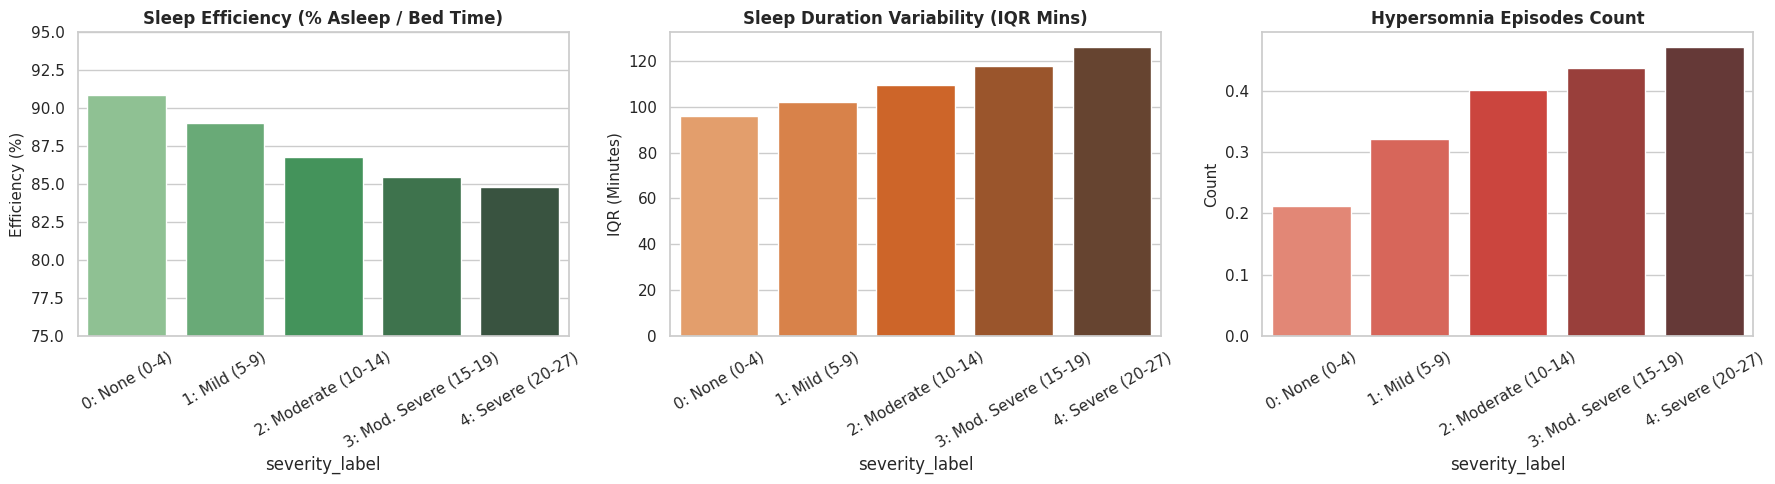

In [6]:
sleep_metrics = [
    'sleep_asleep_weekday_mean', 'sleep_in_bed_weekday_mean', 
    'sleep_ratio_asleep_in_bed_weekday_mean', 'sleep_asleep_iqr', 
    'sleep_main_start_hour_adj_median', 'sleep__hypersomnia_count_', 'sleep__hyposomnia_count_'
]

sleep_summary = valid_phq.groupby('severity_label')[sleep_metrics].mean()
print("=== Sleep Architecture Summary across Depression Categories ===")
print(sleep_summary.round(2))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Sleep Efficiency
sns.barplot(x=sleep_summary.index, y=sleep_summary['sleep_ratio_asleep_in_bed_weekday_mean']*100, palette='Greens_d', ax=axes[0])
axes[0].set_title('Sleep Efficiency (% Asleep / Bed Time)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Efficiency (%)', fontsize=11)
axes[0].set_ylim(75, 95)
axes[0].tick_params(axis='x', rotation=30)

# Sleep Variability
sns.barplot(x=sleep_summary.index, y=sleep_summary['sleep_asleep_iqr'], palette='Oranges_d', ax=axes[1])
axes[1].set_title('Sleep Duration Variability (IQR Mins)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('IQR (Minutes)', fontsize=11)
axes[1].tick_params(axis='x', rotation=30)

# Hypersomnia Count
sns.barplot(x=sleep_summary.index, y=sleep_summary['sleep__hypersomnia_count_'], palette='Reds_d', ax=axes[2])
axes[2].set_title('Hypersomnia Episodes Count', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Count', fontsize=11)
axes[2].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()


---
## 6. Demographic, Socioeconomic, & Clinical Comorbidities
Analyzing age, sex, financial hardship, migraines, neuropathic pain, and arthritis.


=== Feature Means across PHQ-9 Severity ===
                         sex  birthyear  educ    bmi  money  \
severity_label                                                
0: None (0-4)           0.38    1980.27  3.72  29.63   0.31   
1: Mild (5-9)           0.22    1979.76  3.52  31.13   0.55   
2: Moderate (10-14)     0.15    1980.49  3.36  32.52   0.78   
3: Mod. Severe (15-19)  0.13    1981.08  3.23  33.05   1.06   
4: Severe (20-27)       0.14    1980.24  3.10  32.63   1.41   

                        comorbid_migraines  comorbid_neuropathic  \
severity_label                                                     
0: None (0-4)                         0.17                  0.10   
1: Mild (5-9)                         0.37                  0.29   
2: Moderate (10-14)                   0.51                  0.44   
3: Mod. Severe (15-19)                0.62                  0.59   
4: Severe (20-27)                     0.68                  0.72   

                        comorbid_arth

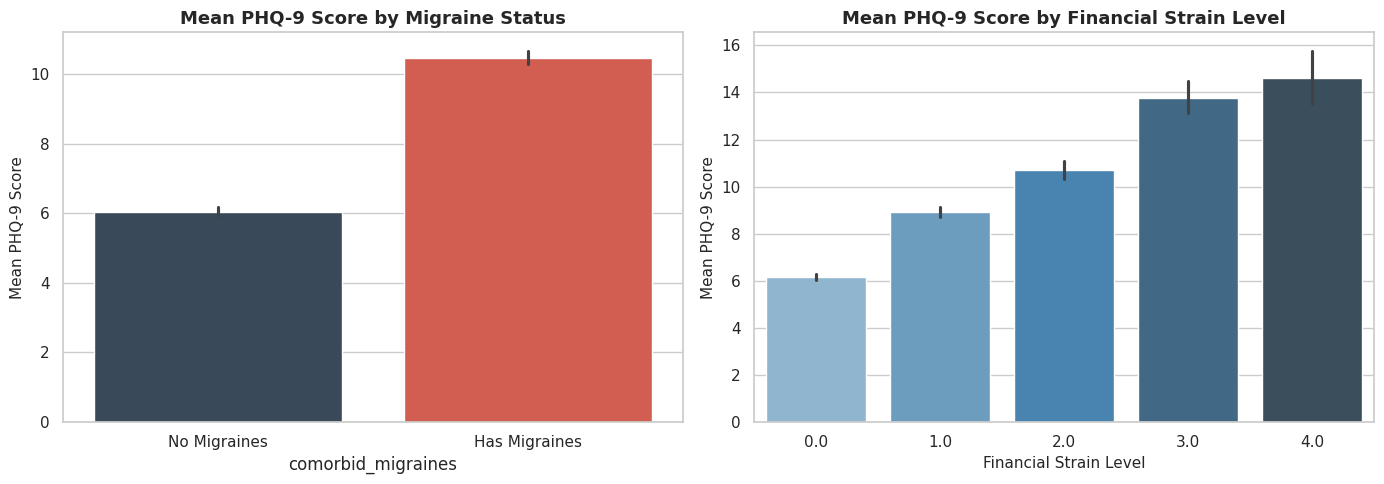

In [7]:
demo_cols = ['sex', 'birthyear', 'educ', 'bmi', 'money', 'comorbid_migraines', 'comorbid_neuropathic', 'comorbid_arthritis']

print("=== Feature Means across PHQ-9 Severity ===")
print(valid_phq.groupby('severity_label')[demo_cols].mean().round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Migraines
sns.barplot(data=valid_phq, x='comorbid_migraines', y='phq9_score_start', palette=['#34495e', '#e74c3c'], ax=axes[0])
axes[0].set_title('Mean PHQ-9 Score by Migraine Status', fontsize=13, fontweight='bold')
axes[0].set_xticklabels(['No Migraines', 'Has Migraines'])
axes[0].set_ylabel('Mean PHQ-9 Score', fontsize=11)

# Financial Strain
sns.barplot(data=valid_phq, x='money', y='phq9_score_start', palette='Blues_d', ax=axes[1])
axes[1].set_title('Mean PHQ-9 Score by Financial Strain Level', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Financial Strain Level', fontsize=11)
axes[1].set_ylabel('Mean PHQ-9 Score', fontsize=11)

plt.tight_layout()
plt.show()


---
## 7. Pearson & Spearman Feature Correlation Rankings
Identification of top positive and negative linear predictors of baseline PHQ-9 score.


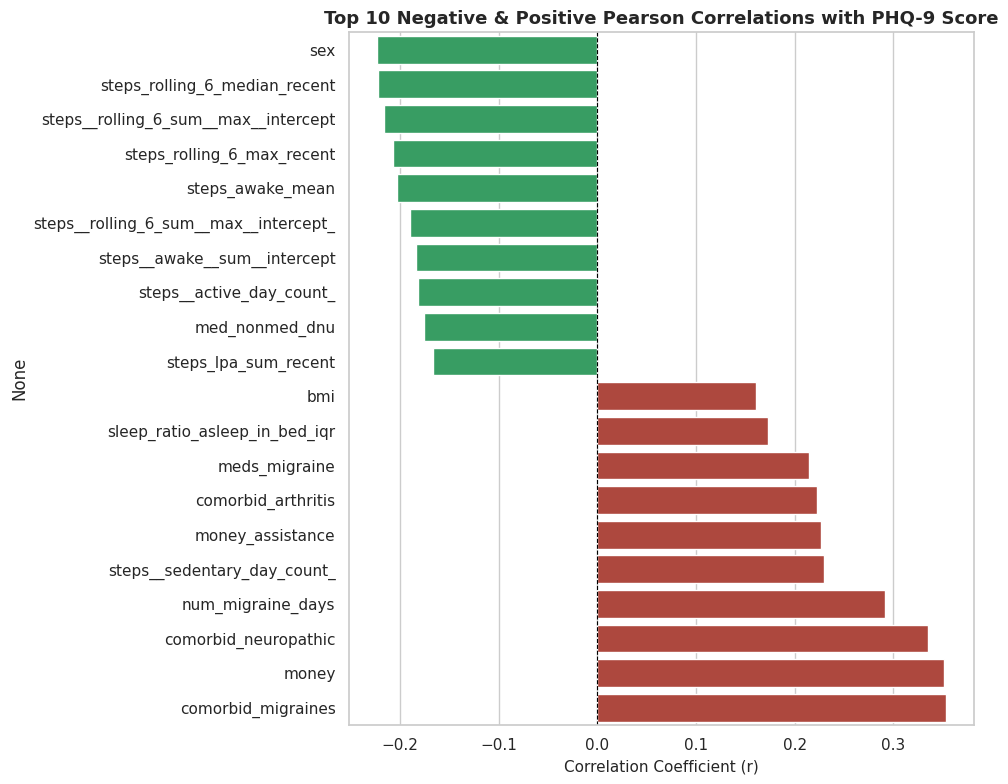

In [8]:
num_cols = df.select_dtypes(include=[np.number]).columns
corrs = df[num_cols].corrwith(df['phq9_score_start']).drop(['phq9_score_start', 'phq9_score_end', 'phq9_cat_start', 'phq9_cat_end']).dropna().sort_values()

top_neg = corrs.head(10)
top_pos = corrs.tail(10)
top_corrs = pd.concat([top_neg, top_pos])

plt.figure(figsize=(10, 8))
colors = ['#27ae60' if x < 0 else '#c0392b' for x in top_corrs.values]
sns.barplot(x=top_corrs.values, y=top_corrs.index, palette=colors)
plt.title('Top 10 Negative & Positive Pearson Correlations with PHQ-9 Score', fontsize=13, fontweight='bold')
plt.xlabel('Correlation Coefficient (r)', fontsize=11)
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.show()


---
## 8. Longitudinal PHQ-9 Transitions & State Persistence
Analyzing how depression categories transition from interval start to interval end.


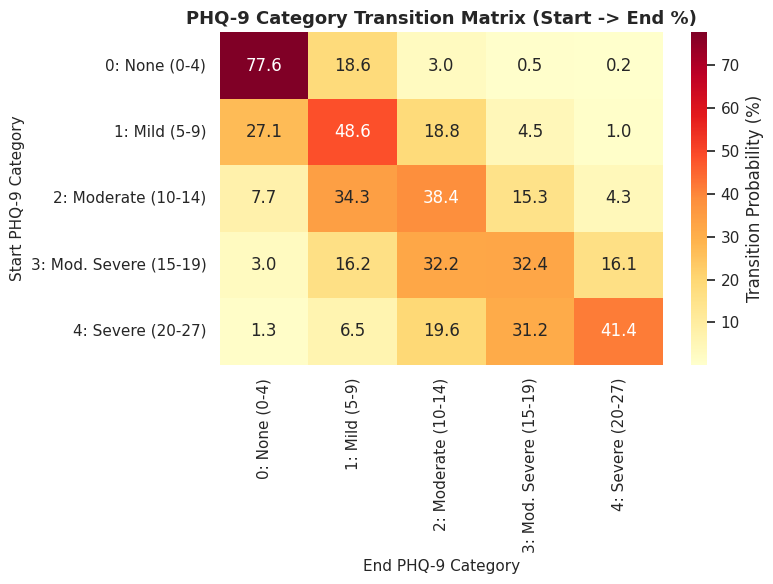

In [9]:
trans_df = valid_phq.dropna(subset=['phq9_cat_end'])
ctable = pd.crosstab(trans_df['phq9_cat_start'], trans_df['phq9_cat_end'], normalize='index') * 100

plt.figure(figsize=(8, 6))
sns.heatmap(ctable, annot=True, fmt='.1f', cmap='YlOrRd', cbar_kws={'label': 'Transition Probability (%)'},
            xticklabels=cat_labels, yticklabels=cat_labels)
plt.title('PHQ-9 Category Transition Matrix (Start -> End %)', fontsize=13, fontweight='bold')
plt.xlabel('End PHQ-9 Category', fontsize=11)
plt.ylabel('Start PHQ-9 Category', fontsize=11)
plt.tight_layout()
plt.show()


---
## 9. Machine Learning Modeling Strategy & Recommendations
Based on the empirical findings from this EDA, here are key modeling considerations for building predictive depression models on this dataset:

1. **CV Group Splitting:**  
   - **CRITICAL:** Use `GroupKFold` or `GroupShuffleSplit` on `user_id`. Because subjects have multiple longitudinal rows (up to 12 periods), standard random splitting will cause severe data leakage across train and test sets.

2. **Handling Unlabeled Intervals (69.6% missing PHQ-9):**  
   - Supervised models can train on the **10,866 labeled rows**.  
   - Semi-supervised learning or self-training / pseudo-labeling can leverage the 24,828 unlabeled sensor intervals.

3. **Feature Engineering Priorities:**  
   - **Interaction Terms:** Sleep Efficiency $\times$ Daily Step Count (capturing overall circadian restfulness vs daytime activity).  
   - **Recent Trend Derivatives:** Features like `steps__awake__sum__coeff` and `sleep__main_efficiency__coeff` represent slope/trend over time and show significant correlation with clinical outcomes.  
   - **Comorbidity Risk Index:** Combining high-impact conditions (migraines + neuropathic pain + arthritis) into a weighted clinical burden score.

4. **Class Imbalance Management:**  
   - Minimal (37%) and Mild (30%) represent 67% of labeled samples, while Moderately Severe (9.7%) and Severe (5.0%) are minority classes.  
   - Apply class weighting (`class_weight='balanced'`) or focal loss for multi-class classification models.
